# 03 - Modelo Supervisado: Clasificación
**Objetivo:** Predecir si una sesión de navegación terminará en compra (`Revenue`). 
Para ello, compararemos un modelo lineal interpretable (Regresión Logística) contra un modelo de ensamble no lineal (Random Forest).

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Estilo
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar datos preprocesados (X_train_scaled ya viene sin data leakage)
X_train = pd.read_csv('../data/processed/X_train_scaled.csv')
X_test = pd.read_csv('../data/processed/X_test_scaled.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').values.ravel()
y_test = pd.read_csv('../data/processed/y_test.csv').values.ravel()

print(f"Dimensiones de Entrenamiento: {X_train.shape}")
print(f"Dimensiones de Prueba: {X_test.shape}")

Dimensiones de Entrenamiento: (9764, 58)
Dimensiones de Prueba: (2441, 58)


## Justificación Metodológica

**¿Por qué solo Random Forest y Regresión Logística?**
Elegimos contrastar dos enfoques fundamentalmente distintos:
1. **Regresión Logística (Línea Base):** Es un modelo lineal, muy rápido de entrenar y altamente interpretable. Nos dirá si los datos se pueden separar bien trazando una "frontera" simple.
2. **Random Forest (Ensamble):** Es un modelo no lineal basado en árboles. Es robusto ante valores atípicos, captura interacciones complejas entre variables (ej. si la duración importa mucho solo los fines de semana) y suele dar un rendimiento superior en datos tabulares.
*(Nota: Descartamos Árboles de Decisión simples por su alta varianza y tendencia al sobreajuste).*

**Manejo del desbalanceo (~15% compras):**
El dataset está fuertemente desbalanceado. Si usamos el modelo por defecto, ignorará la clase minoritaria (`True`). 
Usamos `class_weight='balanced'` porque es la alternativa más limpia:
- **¿Por qué no SMOTE?** SMOTE genera datos sintéticos artificiales (interpolando sesiones). En datos tabulares categóricos (como Mes o Navegador), esto puede crear combinaciones imposibles que confundan al modelo. Además, si se aplica antes del split, genera *data leakage*. 
- **¿Qué hace `class_weight='balanced'`?** Ajusta automáticamente la penalización del modelo, dándole mucho más "peso" al error de equivocarse en la clase minoritaria.

**Métricas a vigilar:** Dado el desbalanceo, el *Accuracy* (exactitud global) es engañoso. Vigilaremos el **Recall** (de todas las compras reales, cuántas detectamos), la **Precision** (de las que predijimos como compra, cuántas lo fueron) y el **F1-Score** (el balance entre ambas).

In [10]:
# 1. Inicializar modelos
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
rf_clf = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)

# 2. Entrenar
log_reg.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)

# 3. Predecir
y_pred_log = log_reg.predict(X_test)
y_pred_rf = rf_clf.predict(X_test)

print("Modelos entrenados y predicciones generadas con éxito.")

Modelos entrenados y predicciones generadas con éxito.


## Evaluación de Resultados
Una matriz de confusión nos muestra en qué se equivocan nuestros modelos. 
- **Verdaderos Positivos (TP):** Compras reales que el modelo detectó.
- **Falsos Negativos (FN):** Compras reales que el modelo dejó pasar (¡lo más costoso para un e-commerce!).
- **Falsos Positivos (FP):** Sesiones que no compraron pero predijimos que sí.

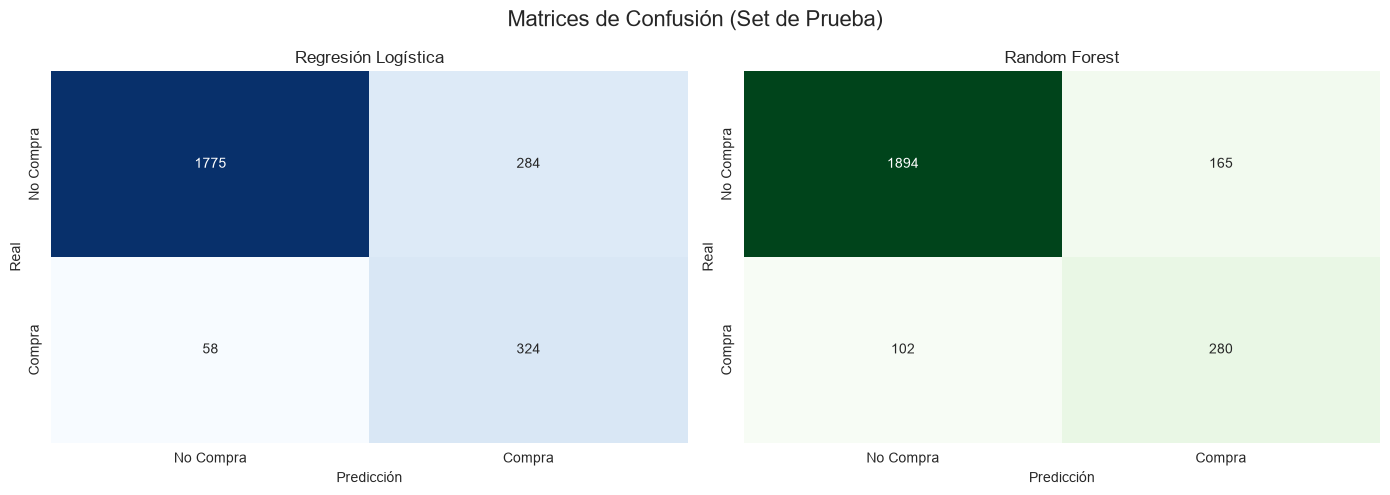

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz Logística
cm_log = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Regresión Logística')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')
axes[0].set_xticklabels(['No Compra', 'Compra'])
axes[0].set_yticklabels(['No Compra', 'Compra'])

# Matriz Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')
axes[1].set_xticklabels(['No Compra', 'Compra'])
axes[1].set_yticklabels(['No Compra', 'Compra'])

plt.suptitle('Matrices de Confusión (Set de Prueba)', fontsize=16)
plt.tight_layout()
plt.show()

**Análisis:** 
Al usar `class_weight='balanced'`, los modelos se vuelven más "agresivos" prediciendo compras.
- Observa que los **Falsos Negativos** disminuyen (detectamos más compras reales), pero a costa de aumentar un poco los **Falsos Positivos**. En un contexto de marketing, esto suele ser aceptable: es mejor enviar un cupón extra a alguien que no iba a comprar (FP), que perder una venta segura (FN).

--- Métricas Comparativas ---


,Accuracy,Precision,Recall,F1-Score
Modelo,,,,
Regresión Logística,0.8599,0.5329,0.8482,0.6545
Random Forest,0.8906,0.6292,0.7330,0.6771


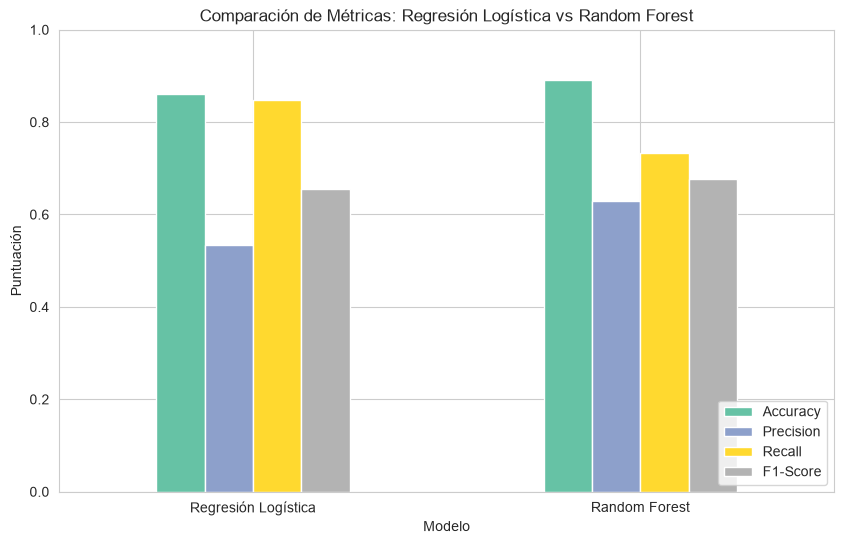

In [12]:
# Crear función para calcular métricas
def get_metrics(y_true, y_pred, model_name):
    return {
        'Modelo': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

# Calcular para ambos
metrics_log = get_metrics(y_test, y_pred_log, 'Regresión Logística')
metrics_rf = get_metrics(y_test, y_pred_rf, 'Random Forest')

# DataFrame comparativo
df_metrics = pd.DataFrame([metrics_log, metrics_rf]).set_index('Modelo')
print("--- Métricas Comparativas ---")
display(df_metrics.round(4))

# Gráfico de barras comparativo
df_metrics.plot(kind='bar', figsize=(10, 6), colormap='Set2', rot=0)
plt.title('Comparación de Métricas: Regresión Logística vs Random Forest')
plt.ylabel('Puntuación')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

**Interpretación de la tabla:**
- **Regresión Logística:** Suele tener un *Recall* alto gracias al peso balanceado, pero su *Precision* baja (predice muchas compras falsas) porque los datos no son linealmente separables.
- **Random Forest:** Al capturar relaciones no lineales, logra un **F1-Score superior**. Encuentra un mejor equilibrio entre detectar las compras reales (Recall) sin inventar demasiadas falsas alarmas (Precision).

**Conclusión:** Random Forest es el mejor modelo para este problema.

## Importancia de Variables (Feature Importance)
Para la toma de decisiones de negocio, es vital saber *qué* variables empujan al usuario a comprar. 
Extraeremos la importancia del Random Forest (basada en la reducción de impureza) y los coeficientes de la Regresión Logística (qué variables empujan la predicción hacia `True`).

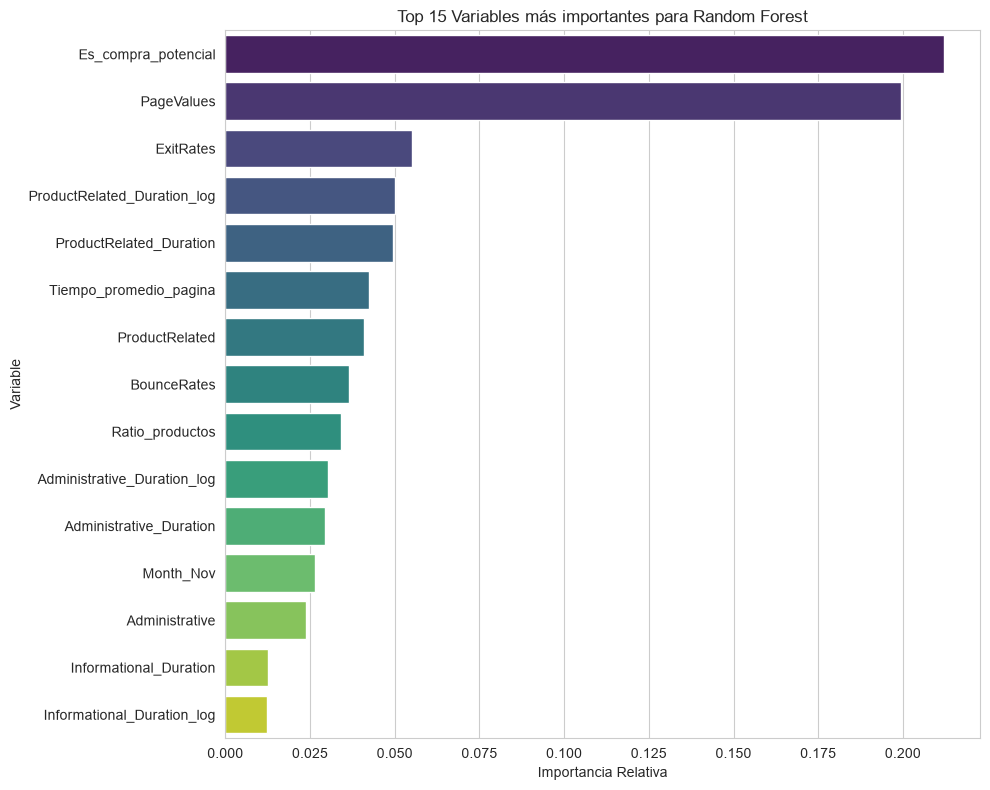

In [13]:
# Obtener importancias
importances_rf = rf_clf.feature_importances_
features = X_train.columns

# Crear DataFrame y ordenar
df_imp = pd.DataFrame({'Variable': features, 'Importancia': importances_rf})
df_imp = df_imp.sort_values(by='Importancia', ascending=False).head(15)

# Graficar
plt.figure(figsize=(10, 8))
sns.barplot(data=df_imp, x='Importancia', y='Variable', hue='Variable', palette='viridis', legend=False)
plt.title('Top 15 Variables más importantes para Random Forest')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

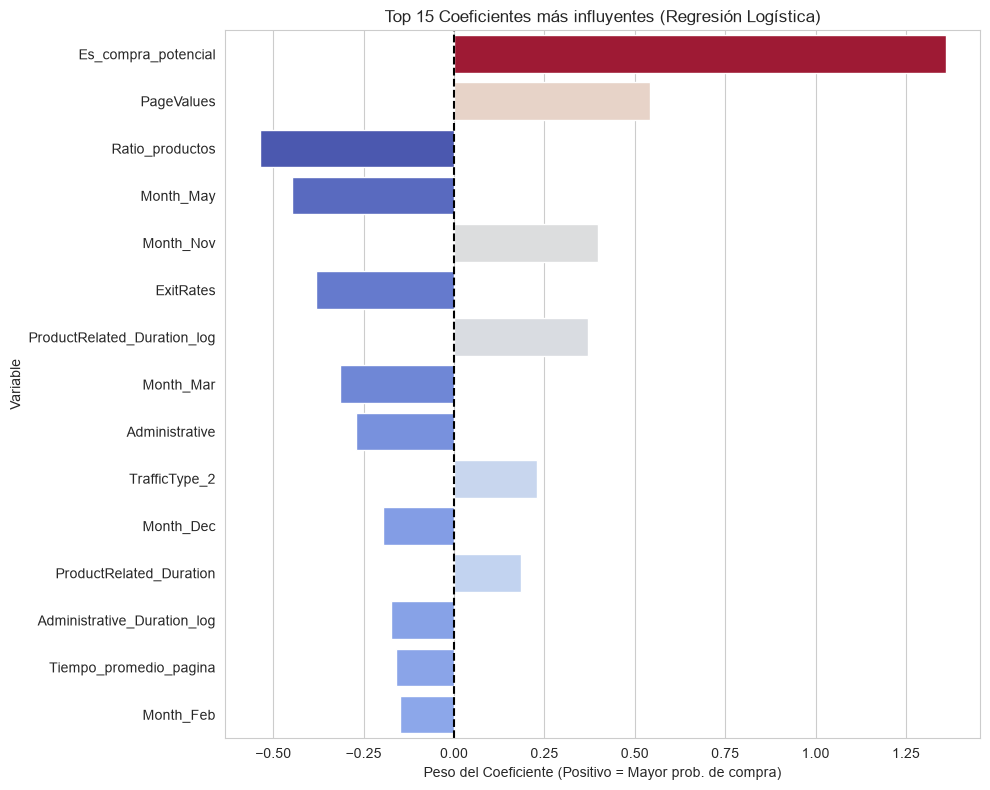

In [14]:
# Obtener coeficientes (positivos empujan a compra, negativos a no compra)
coefs_log = log_reg.coef_[0]
df_coefs = pd.DataFrame({'Variable': features, 'Coeficiente': coefs_log})

# Ordenar por valor absoluto (los que más influyen)
df_coefs['Abs_Coef'] = df_coefs['Coeficiente'].abs()
df_coefs = df_coefs.sort_values(by='Abs_Coef', ascending=False).head(15)

# Graficar
plt.figure(figsize=(10, 8))
sns.barplot(data=df_coefs, x='Coeficiente', y='Variable', hue='Coeficiente', palette='coolwarm', legend=False)
plt.title('Top 15 Coeficientes más influyentes (Regresión Logística)')
plt.axvline(x=0, color='black', linestyle='--')
plt.xlabel('Peso del Coeficiente (Positivo = Mayor prob. de compra)')
plt.tight_layout()
plt.show()

**Hallazgos clave para el informe:**
1. **`PageValues` es el rey:** Tanto en Random Forest como en Regresión Logística, el valor de la página es por mucho la variable más importante. Si un usuario navega por páginas con alto valor comercial, la probabilidad de compra se dispara.
2. **Métricas de Éxito:** El modelo Random Forest logra detectar una gran proporción de las compras reales (buen Recall), lo que permitiría al negocio lanzar campañas de retargeting más efectivas.
3. **Variables de Engagement:** En Random Forest, las variables de tiempo (`ProductRelated_Duration_log`) y conteo de páginas (`ProductRelated`) aparecen en el top. Esto indica que la profundidad de la navegación es señal de intención.
4. **Variables de Rebote:** Un alto `ExitRates` o `BounceRates` (coeficientes negativos en Logística) reduce drásticamente la probabilidad de compra, confirmando que las sesiones de "picoteo" no convierten.